In [1]:
%pip install rembg

  Using cached pooch-1.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached pymatting-1.1.15-py3-none-any.whl.metadata (8.7 kB)
  Using cached numpy-2.2.6-cp310-cp310-win_amd64.whl.metadata (60 kB)
   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.7 MB ? eta -:--:--
   ----------- ---------------------------- 0.8/2.7 MB 2.2 MB/s eta 0:00:01
   ------------------- -------------------- 1.3/2.7 MB 2.2 MB/s eta 0:00:01
   -------------------------- ------------- 1.8/2.7 MB 2.2 MB/s eta 0:00:01
   ------------------------------ --------- 2.1/2.7 MB 2.2 MB/s eta 0:00:01
   ---------------------------------------- 2.7/2.7 MB 2.2 MB/s  0:00:01
   ---------------------------------------- 0.0/38.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/38.1 MB ? eta -:--:--
    --------------------------------------- 0.8/38.1 MB 2.2 MB/s eta 0:00:17
   - -------------------------------------- 1.3/38.1 MB 2.2 MB/s eta 0

In [3]:
%pip install onnxruntime

  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/13.5 MB ? eta -:--:--
    --------------------------------------- 0.3/13.5 MB ? eta -:--:--
   -- ------------------------------------- 0.8/13.5 MB 2.0 MB/s eta 0:00:07
   --- ------------------------------------ 1.0/13.5 MB 2.0 MB/s eta 0:00:07
   ---- ----------------------------------- 1.6/13.5 MB 2.1 MB/s eta 0:00:06
   ------ --------------------------------- 2.1/13.5 MB 2.1 MB/s eta 0:00:06
   ------- -------------------------------- 2.6/13.5 MB 2.1 MB/s eta 0:00:06
   --------- ------------------------------ 3.1/13.5 MB 2.1 MB/s eta 0:00:05
   ---------- ----------------------------- 3.4/13.5 MB 2.2 MB/s eta 0:00:05
   ----------- ---------------------------- 3.9/13.5 MB 2.2 MB/s eta 0:00:05
   ------------- -------------------------- 4.5/13.5 MB 2.2 MB/s eta 0:00:05
   -------------- ------------------------

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import kagglehub
from rembg import remove
from PIL import Image
from tqdm import tqdm

# ==========================================
# 1. DOWNLOAD DATASET
# ==========================================

path = kagglehub.dataset_download(
    "sachinkumar413/diabetic-retinopathy-dataset"
)

data_dir = path

print("Dataset path:", data_dir)
print("Folders:", os.listdir(data_dir))


# ==========================================
# 2. CREATE DATAFRAME
# ==========================================

filepaths = []
labels = []

for class_name in os.listdir(data_dir):
    class_path = os.path.join(data_dir, class_name)

    if os.path.isdir(class_path):
        for img_name in os.listdir(class_path):
            if img_name.lower().endswith((".jpg", ".jpeg", ".png")):
                filepaths.append(os.path.join(class_path, img_name))
                labels.append(class_name)

df = pd.DataFrame({
    "filepaths": filepaths,
    "labels": labels
})

print("\nInitial distribution:")
print(df["labels"].value_counts())
print("Total images:", len(df))



Dataset path: C:\Users\User\.cache\kagglehub\datasets\sachinkumar413\diabetic-retinopathy-dataset\versions\1
Folders: ['Healthy', 'Mild DR', 'Moderate DR', 'Proliferate DR', 'Severe DR']

Initial distribution:
labels
Healthy           1000
Moderate DR        900
Mild DR            370
Proliferate DR     290
Severe DR          190
Name: count, dtype: int64
Total images: 2750


In [4]:

# ==========================================
# 3. PREPROCESS LIKE PAPER
# ==========================================

IMG_SIZE = 180

def preprocess_image_paper(img_path):
    # Load image
    img = Image.open(img_path).convert("RGB")

    # Background removal using REMBG
    img = remove(img)

    # Convert PIL -> NumPy
    img = np.array(img.convert("RGB"))

    # Grayscale conversion using OpenCV
    img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # Resize to 180x180
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    # Normalize
    img = img.astype("float32") / 255.0

    # Add channel dimension: (180, 180, 1)
    img = np.expand_dims(img, axis=-1)

    return img


In [5]:
# ==========================================
# 4. APPLY PREPROCESSING
# ==========================================

X = []
y = []

for _, row in tqdm(df.iterrows(), total=len(df)):
    try:
        img = preprocess_image_paper(row["filepaths"])
        X.append(img)
        y.append(row["labels"])
    except Exception as e:
        print("Error:", row["filepaths"], e)

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

  0%|          | 0/2750 [00:00<?, ?it/s]Downloading data from 'https://github.com/danielgatis/rembg/releases/download/v0.0.0/u2net.onnx' to file 'C:\Users\User\.u2net\u2net.onnx'.






































































































































































































































































































































































































































































































































































































































































































































































































100%|########################################|

KeyboardInterrupt: 

In [ ]:
import matplotlib.pyplot as plt

idx = 0

original = Image.open(df["filepaths"].iloc[idx]).convert("RGB")
processed = preprocess_image_paper(df["filepaths"].iloc[idx])

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed.squeeze(), cmap="gray")
plt.title("Paper preprocessing")
plt.axis("off")

plt.show()

In [3]:
import os
import cv2
import numpy as np
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

c:\Users\User\Documents\tensor_py_engineer_stuff\tf_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# 1. LOAD DATASET

path = kagglehub.dataset_download(
    "sachinkumar413/diabetic-retinopathy-dataset"
)

data_dir = path

filepaths = []
labels = []

for class_name in os.listdir(data_dir):
    class_path = os.path.join(data_dir, class_name)

    if os.path.isdir(class_path):
        for img_name in os.listdir(class_path):
            if img_name.lower().endswith((".jpg", ".jpeg", ".png")):
                filepaths.append(os.path.join(class_path, img_name))
                labels.append(class_name)

df = pd.DataFrame({
    "filepaths": filepaths,
    "labels": labels
})

print(df["labels"].value_counts())
print("Total images:", len(df))

labels
Healthy           1000
Moderate DR        900
Mild DR            370
Proliferate DR     290
Severe DR          190
Name: count, dtype: int64
Total images: 2750


In [5]:
IMG_SIZE = 180

def preprocess_image(img_path):
    img = cv2.imread(img_path)

    if img is None:
        raise ValueError(f"Could not read image: {img_path}")

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # background crop only
    _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    coords = cv2.findNonZero(thresh)

    if coords is not None:
        x, y, w, h = cv2.boundingRect(coords)
        gray = gray[y:y+h, x:x+w]

    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
    gray = gray.astype("float32") / 255.0
    gray = np.expand_dims(gray, axis=-1)

    return gray

In [6]:
X = []
y = []

for _, row in tqdm(df.iterrows(), total=len(df)):
    X.append(preprocess_image(row["filepaths"]))
    y.append(row["labels"])

X = np.array(X)
y = np.array(y)

print("X:", X.shape)
print("y:", y.shape)

100%|██████████| 2750/2750 [00:09<00:00, 278.17it/s]


X: (2750, 180, 180, 1)
y: (2750,)


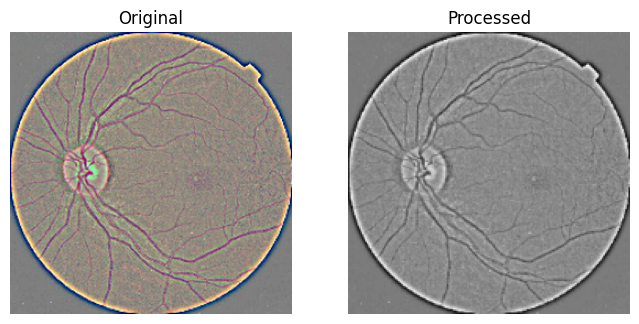

In [7]:
idx = 0

original = cv2.imread(df["filepaths"].iloc[idx])
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

processed = preprocess_image(df["filepaths"].iloc[idx])

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed.squeeze(), cmap="gray")
plt.title("Processed")
plt.axis("off")

plt.show()

In [8]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

print("Classes:", encoder.classes_)

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    stratify=y_encoded,
    random_state=42
)

Classes: ['Healthy' 'Mild DR' 'Moderate DR' 'Proliferate DR' 'Severe DR']


In [9]:
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator()

train_generator = train_datagen.flow(
    X_train,
    y_train,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_generator = val_datagen.flow(
    X_val,
    y_val,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [10]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))
print(class_weights)

{np.int64(0): np.float64(0.55), np.int64(1): np.float64(1.4864864864864864), np.int64(2): np.float64(0.6111111111111112), np.int64(3): np.float64(1.896551724137931), np.int64(4): np.float64(2.8947368421052633)}


In [11]:
model = Sequential([
    Conv2D(16, (3, 3), activation="relu", padding="same", input_shape=(180, 180, 1)),
    Conv2D(16, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

c:\Users\User\Documents\tensor_py_engineer_stuff\tf_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 180, 180, 16)   │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,991,317 (15.23 MB)

 Trainable params: 3,991,317 (15.23 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=80,
    callbacks=[early_stop],
    class_weight=class_weights
)

Epoch 1/80
69/69 ━━━━━━━━━━━━━━━━━━━━ 13s 175ms/step - accuracy: 0.3841 - loss: 1.5220 - val_accuracy: 0.5945 - val_loss: 1.1577
Epoch 2/80
69/69 ━━━━━━━━━━━━━━━━━━━━ 11s 166ms/step - accuracy: 0.4632 - loss: 1.3919 - val_accuracy: 0.4545 - val_loss: 1.1771
Epoch 3/80
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 168ms/step - accuracy: 0.4955 - loss: 1.3462 - val_accuracy: 0.5818 - val_loss: 1.1484
Epoch 4/80
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 167ms/step - accuracy: 0.4645 - loss: 1.3333 - val_accuracy: 0.5764 - val_loss: 1.0979
Epoch 5/80
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 167ms/step - accuracy: 0.4864 - loss: 1.3169 - val_accuracy: 0.5091 - val_loss: 1.1269
Epoch 6/80
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 168ms/step - accuracy: 0.4900 - loss: 1.3084 - val_accuracy: 0.5764 - val_loss: 1.1443
Epoch 7/80
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 169ms/step - accuracy: 0.4859 - loss: 1.3051 - val_accuracy: 0.5218 - val_loss: 1.0741
Epoch 8/80
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 168ms/step - accuracy: 0.4664 - loss: 1.2774 - val_accu

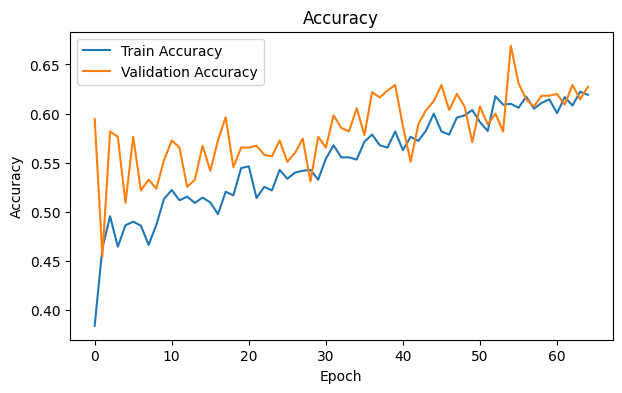

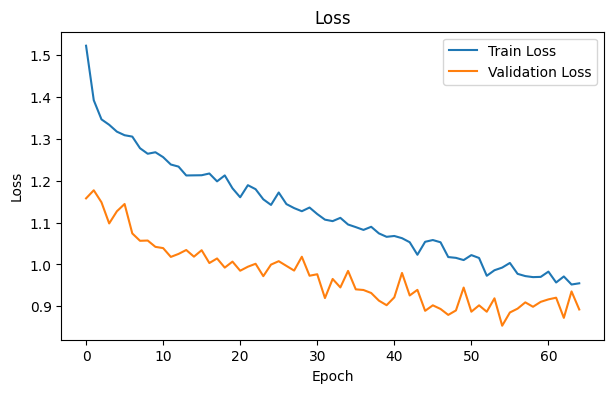

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step


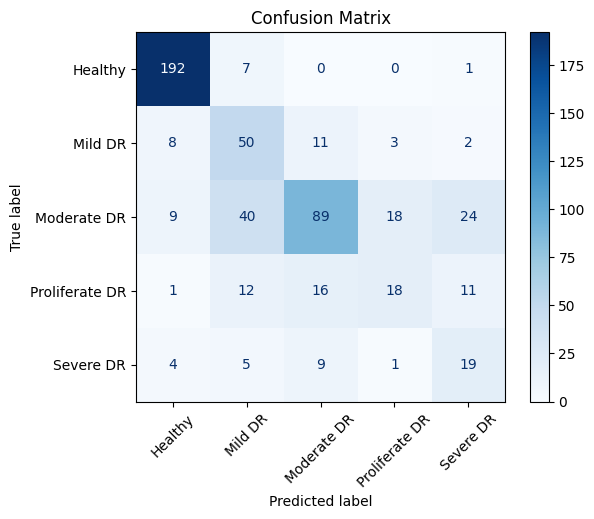

                precision    recall  f1-score   support

       Healthy       0.90      0.96      0.93       200
       Mild DR       0.44      0.68      0.53        74
   Moderate DR       0.71      0.49      0.58       180
Proliferate DR       0.45      0.31      0.37        58
     Severe DR       0.33      0.50      0.40        38

      accuracy                           0.67       550
     macro avg       0.57      0.59      0.56       550
  weighted avg       0.69      0.67      0.67       550



In [14]:
y_pred_probs = model.predict(X_val)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_val, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

disp.plot(cmap="Blues", values_format="d", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.show()

print(classification_report(
    y_val,
    y_pred,
    target_names=encoder.classes_
))

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step


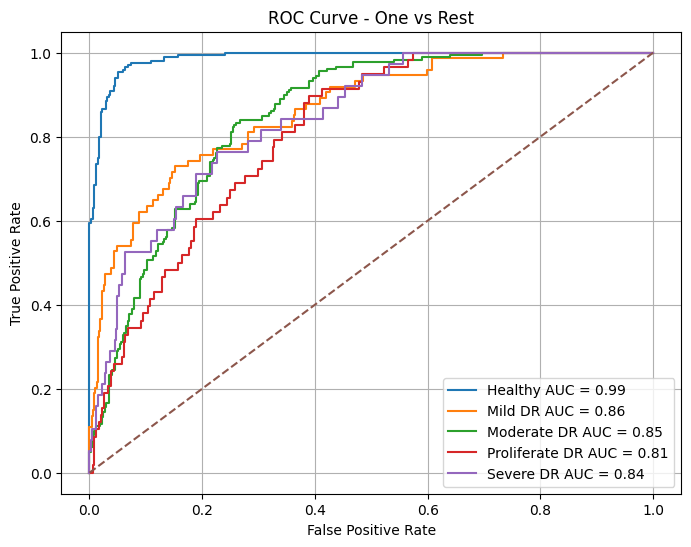

In [28]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

# probabilities για κάθε class
y_score = model.predict(X_val)

# one-hot τα πραγματικά labels
n_classes = len(encoder.classes_)

y_val_bin = label_binarize(
    y_val,
    classes=np.arange(n_classes)
)

plt.figure(figsize=(8, 6))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_val_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{encoder.classes_[i]} AUC = {roc_auc:.2f}"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve - One vs Rest")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()